# Atrasos de entrega da Olist em 2018: causa raiz e efeito da greve dos caminhoneiros

Dois problemas reais de operação, com duas ferramentas diferentes:

1. **Diagnóstico de causa raiz:** em fevereiro e março de 2018 a taxa de atraso quadruplicou. **Onde** a piora aconteceu: na mistura de destinos, no vendedor, no transporte ou na promessa de prazo?
2. **Efeito causal de um evento externo:** em 21 de maio de 2018 começou a greve nacional dos caminhoneiros, que durou cerca de 10 dias. **Quanto** ela atrasou as entregas e quantas compras deixaram de acontecer?

**Dados:** cerca de 96 mil pedidos entregues da Olist, 2016–2018 ([Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), CC BY-NC-SA 4.0). A tabela é gerada por `scripts/preparar_olist.py`.

**Etapas de cada pedido:** compra → **postagem** (o vendedor entrega o pacote à transportadora) → **entrega** ao cliente. O pedido está atrasado se chega depois da data prometida na compra.

In [1]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from causal.causa_raiz import atraso_simulado, decompor_mix_taxa, fator_por_grupo
from causal.estilo import COR, aplicar, br, fonte, subtitulo
from causal.its import contrafactual, estimar_evento

warnings.filterwarnings("ignore")
aplicar()
FONTE = "Fonte: Olist Brazilian E-Commerce Public Dataset · elaboração: Cézar Bento"
FIG = "../figures/"

pedidos = pd.read_csv("../data/olist_entregas.csv.gz", parse_dates=["compra", "aprovacao", "postagem", "entrega", "prometido"])
pedidos["atraso"] = (pedidos.entrega.dt.normalize() > pedidos.prometido).astype(int)
pedidos["d_post"] = (pedidos.postagem - pedidos.compra.dt.normalize()).dt.total_seconds() / 86400
pedidos["d_transp"] = (pedidos.entrega - pedidos.postagem).dt.total_seconds() / 86400
pedidos["d_prazo"] = (pedidos.prometido - pedidos.compra.dt.normalize()).dt.days + 1
REGIAO = {"SP": "SP", "RJ": "RJ", "MG": "MG", "ES": "ES", "PR": "Sul", "SC": "Sul", "RS": "Sul"}
pedidos["regiao"] = pedidos.uf_cliente.map(REGIAO).fillna("Norte, Nordeste e Centro-Oeste")
print(f"{br(len(pedidos))} pedidos entregues · atraso médio: {pedidos.atraso.mean():.1%}")

96.469 pedidos entregues · atraso médio: 6.8%


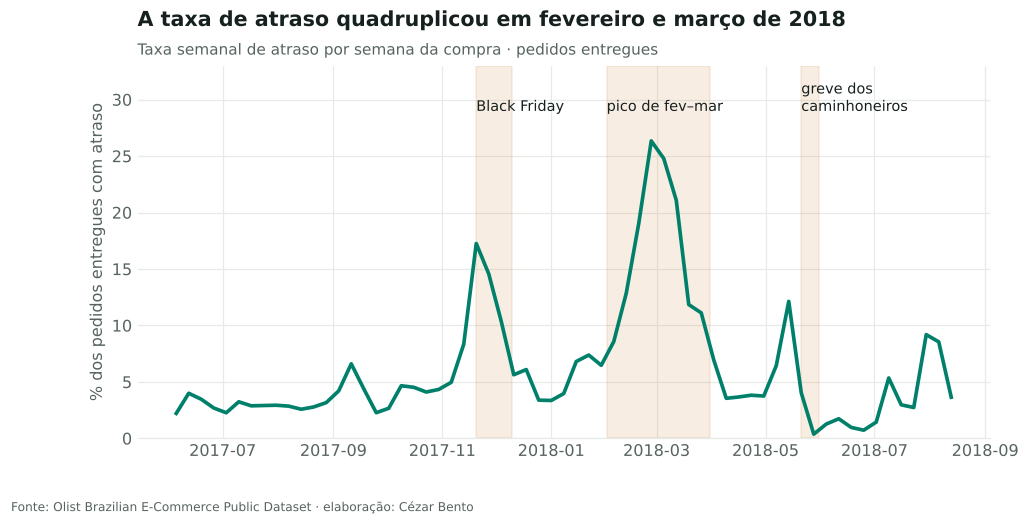

In [2]:
semana = pedidos[(pedidos.compra >= "2017-06-05") & (pedidos.compra < "2018-08-20")]
taxa = semana.groupby(semana.compra.dt.to_period("W-SUN").dt.start_time).atraso.mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(taxa.index, taxa.values, color=COR["principal"], lw=2.4)
destaques = [("2017-11-20", "2017-12-10", "Black Friday"), ("2018-02-01", "2018-03-31", "pico de fev–mar"),
             ("2018-05-21", "2018-05-31", "greve dos\ncaminhoneiros")]
for ini, fim, rotulo in destaques:
    ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fim), color=COR["destaque"], alpha=0.12)
    ax.text(pd.Timestamp(ini), 29, rotulo, fontsize=9.5, color=COR["texto"])
ax.set_ylim(0, 33); ax.set_ylabel("% dos pedidos entregues com atraso")
ax.set_title("A taxa de atraso quadruplicou em fevereiro e março de 2018")
subtitulo(ax, "Taxa semanal de atraso por semana da compra · pedidos entregues")
fonte(fig, FONTE)
fig.savefig(FIG + "11_atraso_semanal.png")

## Parte 1 — Causa raiz do pico de fevereiro e março

Comparo o pico (compras de fevereiro e março de 2018) com um período normal sem datas especiais (setembro e outubro de 2017).

### 1.1 Foi a mistura de destinos ou a piora dentro de cada região?

In [3]:
base = pedidos[(pedidos.compra >= "2017-09-01") & (pedidos.compra < "2017-11-01")]
pico = pedidos[(pedidos.compra >= "2018-02-01") & (pedidos.compra < "2018-04-01")]
print(f"Atraso: {base.atraso.mean():.1%} no período normal → {pico.atraso.mean():.1%} no pico")

mix = decompor_mix_taxa(base, pico, "regiao", "atraso")
efeito_taxa, efeito_mix = mix.efeito_taxa.sum(), mix.efeito_composicao.sum()
print(f"Variação total: {(efeito_taxa + efeito_mix) * 100:+.1f} p.p. = piora dentro das regiões {efeito_taxa * 100:+.1f} p.p. "
      f"+ mudança na mistura de destinos {efeito_mix * 100:+.1f} p.p.")
print()
tabela = mix[["peso_base", "peso_pico", "mean_base", "mean_pico", "contribuicao"]].copy()
tabela.columns = ["% pedidos (normal)", "% pedidos (pico)", "atraso (normal)", "atraso (pico)", "contribuição (p.p.)"]
print((tabela * 100).round(1).to_string())

Atraso: 4.3% no período normal → 16.6% no pico
Variação total: +12.4 p.p. = piora dentro das regiões +12.5 p.p. + mudança na mistura de destinos -0.1 p.p.

                                % pedidos (normal)  % pedidos (pico)  atraso (normal)  atraso (pico)  contribuição (p.p.)
regiao                                                                                                                   
RJ                                            14.4              12.9              6.0           34.3                  3.5
Norte, Nordeste e Centro-Oeste                19.0              17.0              8.2           24.1                  2.5
SP                                            38.2              41.3              3.2            8.4                  2.3
Sul                                           14.1              14.6              3.0           15.9                  1.9
MG                                            12.0              12.1              1.0           14.6            

A mistura de destinos praticamente não mudou. A piora aconteceu **dentro de todas as regiões**, com o Rio de Janeiro e as regiões mais distantes contribuindo mais. Não foi "mais pedidos para lugares difíceis".

### 1.2 Qual etapa piorou?

Simulo o período do pico com uma etapa de cada vez devolvida ao comportamento normal da sua região (a duração de cada pedido é multiplicada pela razão entre as medianas normal e do pico). Quanto da piora some?

In [4]:
fatores = {etapa: fator_por_grupo(base, pico, "regiao", coluna)
           for etapa, coluna in [("postagem", "d_post"), ("transporte", "d_transp"), ("prazo", "d_prazo")]}
cenarios = {
    "Observado no pico": atraso_simulado(pico),
    "Vendedor no ritmo normal": atraso_simulado(pico, fator_postagem=fatores["postagem"]),
    "Promessa de prazo normal": atraso_simulado(pico, fator_prazo=fatores["prazo"]),
    "Transporte no ritmo normal": atraso_simulado(pico, fator_transporte=fatores["transporte"]),
}
piora = cenarios["Observado no pico"] - base.atraso.mean()
for nome, v in cenarios.items():
    explicado = (cenarios["Observado no pico"] - v) / piora
    print(f"{nome:>28}: atraso de {v:.1%} · explica {explicado:.0%} da piora")
print()
medianas = pd.DataFrame({"normal": base[["d_post", "d_transp", "d_prazo"]].median(), "pico": pico[["d_post", "d_transp", "d_prazo"]].median()})
medianas.index = ["dias até a postagem", "dias de transporte", "prazo prometido (dias)"]
print(medianas.round(1).to_string())
print()
print("Mediana de dias de transporte por região:")
print(pd.DataFrame({"normal": base.groupby("regiao").d_transp.median(), "pico": pico.groupby("regiao").d_transp.median()}).round(1).to_string())

           Observado no pico: atraso de 16.6% · explica 0% da piora
    Vendedor no ritmo normal: atraso de 16.5% · explica 1% da piora
    Promessa de prazo normal: atraso de 17.3% · explica -5% da piora
  Transporte no ritmo normal: atraso de 7.3% · explica 76% da piora

                        normal  pico
dias até a postagem        2.9   3.0
dias de transporte         7.1  10.6
prazo prometido (dias)    24.0  24.0

Mediana de dias de transporte por região:
                                normal  pico
regiao                                      
ES                                 9.1  14.0
MG                                 6.8  10.9
Norte, Nordeste e Centro-Oeste    12.3  16.8
RJ                                 8.2  16.1
SP                                 4.8   5.9
Sul                                9.0  13.2


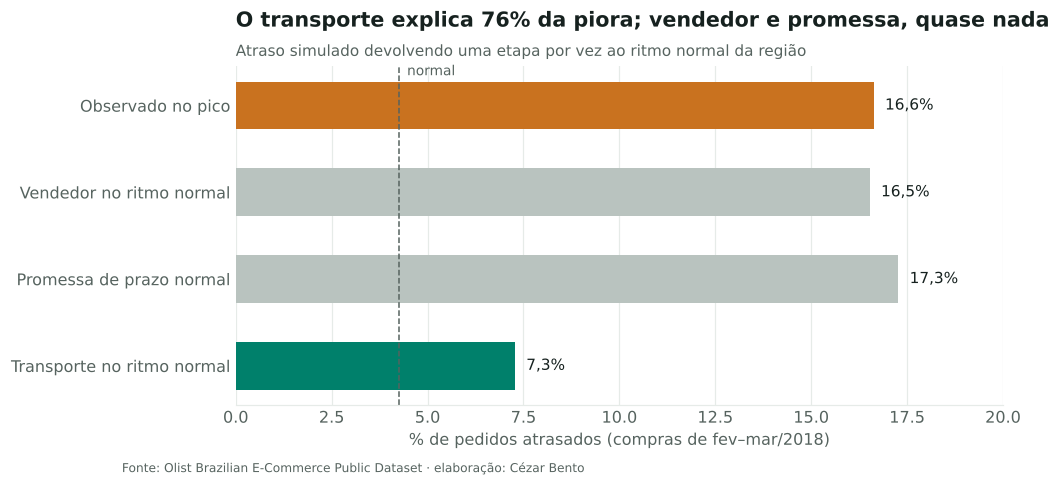

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
nomes = list(cenarios)
valores = [cenarios[k] * 100 for k in nomes]
cores = [COR["destaque"], COR["contexto"], COR["contexto"], COR["principal"]]
ax.barh(nomes[::-1], valores[::-1], color=cores[::-1], height=0.55)
for i, v in enumerate(valores[::-1]):
    ax.text(v + 0.3, i, f"{br(v, 1)}%", va="center", fontsize=10, color=COR["texto"])
ax.axvline(base.atraso.mean() * 100, color=COR["texto2"], lw=1, ls="--")
ax.text(base.atraso.mean() * 100 + 0.2, 3.35, "normal", fontsize=9, color=COR["texto2"])
ax.set_xlim(0, 20); ax.grid(axis="y", visible=False); ax.set_xlabel("% de pedidos atrasados (compras de fev–mar/2018)")
expl = (cenarios["Observado no pico"] - cenarios["Transporte no ritmo normal"]) / piora
ax.set_title(f"O transporte explica {br(expl * 100)}% da piora; vendedor e promessa, quase nada")
subtitulo(ax, "Atraso simulado devolvendo uma etapa por vez ao ritmo normal da região")
fonte(fig, FONTE)
fig.savefig(FIG + "12_causa_raiz_etapas.png")

**Diagnóstico:** a causa raiz técnica está no **transporte**. O tempo entre a postagem e a entrega subiu em todas as regiões, quase dobrando no Rio de Janeiro, enquanto os vendedores despacharam no ritmo de sempre e a promessa de prazo não mudou. A parte que o transporte não explica vem da cauda: alguns pedidos atrasaram muito mais que a mediana da sua região.

**O que os dados não dizem:** *por que* o transporte piorou. Candidatos externos, como a operação dos Correios, chuvas ou o pós-Carnaval, precisam ser confirmados com dados das transportadoras. O valor do diagnóstico é apontar **onde procurar**, e com ele a conversa deixa de ser "os vendedores estão lentos" e vai direto ao contrato de transporte.

**Ação sugerida:** monitorar o tempo de transporte por região e transportadora como indicador antecedente, e ajustar a promessa de prazo quando ele sobe. Em março a promessa ficou igual enquanto o transporte dobrava.

## Parte 2 — Efeito causal da greve dos caminhoneiros

A greve durou de 21 a 31 de maio de 2018. Não há grupo de controle, porque o país inteiro foi afetado ao mesmo tempo. O desenho usado é a **série temporal interrompida**: modela-se o comportamento normal antes do evento (nível, tendência e dia da semana) e mede-se o desvio durante o evento.

**Exposição definida antes de olhar o efeito:** pacotes postados entre 18 de maio (sexta antes da greve, ainda em trânsito quando ela começou) e 31 de maio (fim da greve). Pré-período: 2 de abril a 17 de maio, depois do pico de fev–mar. Pós-período: junho até meados de julho.

In [6]:
dias_uteis = pedidos[pedidos.postagem.dt.dayofweek < 5]
por_dia = dias_uteis.groupby(dias_uteis.postagem.dt.normalize()).agg(pacotes=("d_transp", "size"), transporte=("d_transp", "mean"))
INI, FIM, PRE, POS = "2018-05-18", "2018-05-31", "2018-04-02", "2018-07-13"

especificacoes = {}
for nome, tend in [("com tendência", True), ("sem tendência", False)]:
    ajuste, X, y, w = estimar_evento(por_dia.transporte, INI, FIM, PRE, POS, tendencia=tend, pesos=por_dia.pacotes)
    especificacoes[nome] = (ajuste, X, y, w)
    lo, hi = ajuste.intervalo("exposicao")
    print(f"{nome}: +{br(ajuste.coef['exposicao'], 2)} dias de transporte em média na janela "
          f"(IC 95%: {br(lo, 2)} a {br(hi, 2)}; p = {ajuste.p_valor('exposicao'):.1e})")

ajuste, X, y, w = especificacoes["com tendência"]
cf = contrafactual(X, ajuste)
janela = (y.index >= INI) & (y.index <= FIM)
excesso = ((y - cf)[janela] * w[janela]).sum()
print(f"\nPacotes postados na janela: {br(w[janela].sum())} · dias de atraso extra somados: {br(excesso)}")
pior = (y - cf)[janela].idxmax()
print(f"Pior dia de postagem: {pior:%d/%m} (+{br((y - cf)[pior], 1)} dias em média, {br(y[pior], 1)} contra {br(cf[pior], 1)} esperados)")

com tendência: +3,10 dias de transporte em média na janela (IC 95%: 2,23 a 3,97; p = 2.2e-12)
sem tendência: +1,88 dias de transporte em média na janela (IC 95%: 0,68 a 3,08; p = 2.1e-03)

Pacotes postados na janela: 2.087 · dias de atraso extra somados: 6.470
Pior dia de postagem: 18/05 (+4,3 dias em média, 12,6 contra 8,3 esperados)


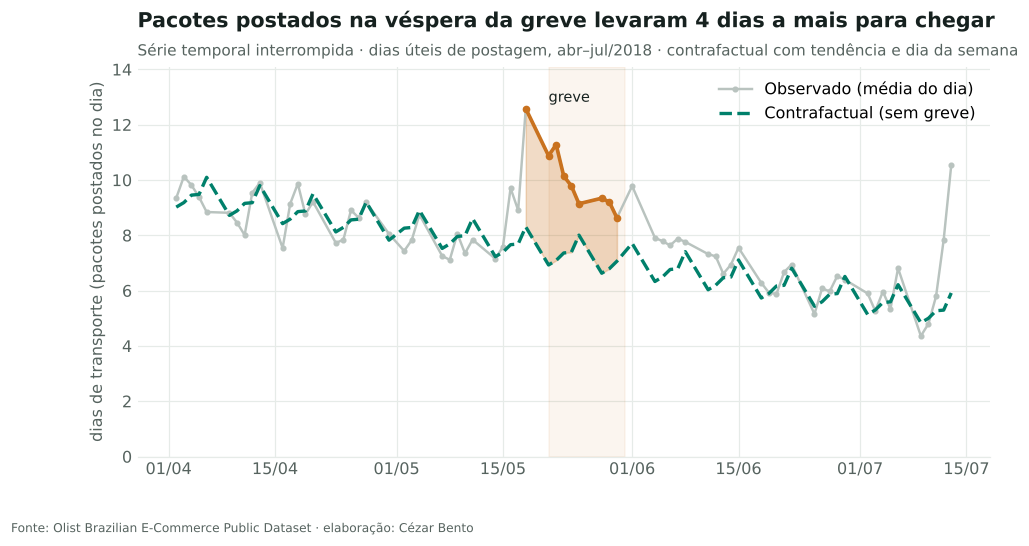

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(y.index, y.values, color=COR["contexto"], lw=1.6, marker="o", ms=3, label="Observado (média do dia)")
ax.plot(cf.index, cf.values, color=COR["principal"], lw=2.2, ls="--", label="Contrafactual (sem greve)")
ax.fill_between(y.index[janela], y[janela], cf[janela], color=COR["destaque"], alpha=0.25)
ax.plot(y.index[janela], y[janela], color=COR["destaque"], lw=2.4, marker="o", ms=4)
ax.axvspan(pd.Timestamp("2018-05-21"), pd.Timestamp("2018-05-31"), color=COR["destaque"], alpha=0.07)
ax.text(pd.Timestamp("2018-05-21"), y.max() * 1.02, "greve", fontsize=9.5, color=COR["texto"])
ax.set_ylabel("dias de transporte (pacotes postados no dia)"); ax.set_ylim(0, y.max() * 1.12); ax.legend(loc="upper right")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
ax.set_title(f"Pacotes postados na véspera da greve levaram {br(y[pior] - cf[pior], 0)} dias a mais para chegar")
subtitulo(ax, "Série temporal interrompida · dias úteis de postagem, abr–jul/2018 · contrafactual com tendência e dia da semana")
fonte(fig, FONTE)
fig.savefig(FIG + "13_greve_transporte.png")

### Quanto o resultado depende das escolhas do modelo?

Duas escolhas mudam o número: incluir ou não a tendência anterior e a definição exata da janela de exposição. Em vez de escolher a mais favorável, mostro todas.

In [8]:
janelas = {"18–31/mai (principal)": ("2018-05-18", "2018-05-31"), "21–31/mai (só a greve)": ("2018-05-21", "2018-05-31"),
           "14–31/mai (mais ampla)": ("2018-05-14", "2018-05-31")}
sens = []
for nome_j, (ini, fim) in janelas.items():
    for nome_t, tend in [("com tendência", True), ("sem tendência", False)]:
        a, *_ = estimar_evento(por_dia.transporte, ini, fim, PRE, POS, tendencia=tend, pesos=por_dia.pacotes)
        lo, hi = a.intervalo("exposicao")
        sens.append({"janela": nome_j, "modelo": nome_t, "efeito (dias)": a.coef["exposicao"], "IC inf": lo, "IC sup": hi})
sens = pd.DataFrame(sens)
print(sens.round(2).to_string(index=False))
print(f"\nFaixa das estimativas: +{br(sens['efeito (dias)'].min(), 1)} a +{br(sens['efeito (dias)'].max(), 1)} dias; "
      f"todos os intervalos acima de zero: {(sens['IC inf'] > 0).all()}")

                janela        modelo  efeito (dias)  IC inf  IC sup
 18–31/mai (principal) com tendência           3.10    2.23    3.97
 18–31/mai (principal) sem tendência           1.88    0.68    3.08
21–31/mai (só a greve) com tendência           2.45    1.34    3.55
21–31/mai (só a greve) sem tendência           1.56    0.53    2.60
14–31/mai (mais ampla) com tendência           2.48    1.28    3.69
14–31/mai (mais ampla) sem tendência           1.04   -0.03    2.10

Faixa das estimativas: +1,0 a +3,1 dias; todos os intervalos acima de zero: False


**Leitura:** todas as versões apontam atraso adicional, mas o tamanho varia de cerca de 1 a 3 dias em média na janela. Em 5 das 6 especificações o intervalo de confiança fica acima de zero; a exceção é a janela mais ampla sem tendência, que mistura dias anteriores à greve e por isso dilui o efeito. O número a reportar é a faixa, não um ponto.

### A greve foi um evento fora do comum? Placebos no tempo

Aplico exatamente o mesmo modelo a janelas de duas semanas em outras datas, de 2017 a 2018. Se janelas comuns também mostrassem "efeitos" desse tamanho, o método estaria só captando ruído.

In [9]:
placebos = []
for ini in pd.date_range("2017-03-06", "2018-07-30", freq="7D"):
    fim = ini + pd.Timedelta(days=13)
    if abs((ini - pd.Timestamp(INI)).days) < 50:
        continue  # janelas que se sobrepõem à greve
    a, *_ = estimar_evento(por_dia.transporte, ini, fim, ini - pd.Timedelta(days=42), fim + pd.Timedelta(days=42),
                           tendencia=True, pesos=por_dia.pacotes)
    placebos.append({"inicio": ini, "efeito": a.coef["exposicao"]})
placebos = pd.DataFrame(placebos).set_index("inicio")
a_greve, *_ = estimar_evento(por_dia.transporte, INI, FIM, pd.Timestamp(INI) - pd.Timedelta(days=42),
                             pd.Timestamp(FIM) + pd.Timedelta(days=42), tendencia=True, pesos=por_dia.pacotes)
efeito_greve = a_greve.coef["exposicao"]
maiores = placebos.efeito.sort_values(ascending=False)
print(f"Greve (mesmo desenho dos placebos): +{br(efeito_greve, 2)} dias")
print(f"{len(placebos)} janelas placebo · maiores 'efeitos':")
print(maiores.head(5).round(2).to_string())
acima = int((placebos.efeito >= efeito_greve).sum())
print(f"Janelas com efeito ≥ ao da greve: {acima} de {len(placebos)} → a greve fica em {acima + 1}º de {len(placebos) + 1} (p ≈ {(acima + 1) / (len(placebos) + 1):.2f})")

Greve (mesmo desenho dos placebos): +2,93 dias
60 janelas placebo · maiores 'efeitos':
inicio
2017-05-29    3.45
2017-06-05    3.05
2017-11-27    2.67
2017-04-17    2.52
2018-07-09    2.35
Janelas com efeito ≥ ao da greve: 2 de 60 → a greve fica em 3º de 61 (p ≈ 0.05)


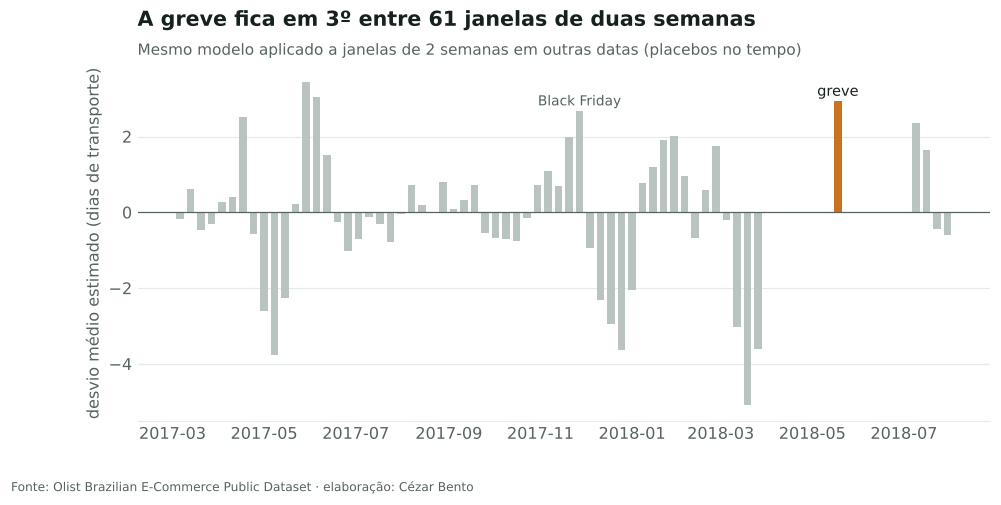

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(placebos.index, placebos.efeito, width=5, color=COR["contexto"])
ax.bar([pd.Timestamp(INI)], [efeito_greve], width=5, color=COR["destaque"])
ax.text(pd.Timestamp(INI), efeito_greve + 0.15, "greve", ha="center", fontsize=9.5, color=COR["texto"])
v = placebos.efeito.loc["2017-11-27"]
ax.text(pd.Timestamp("2017-11-27"), v + 0.15, "Black Friday", ha="center", fontsize=9, color=COR["texto2"])
ax.axhline(0, color=COR["texto2"], lw=0.8); ax.grid(axis="x", visible=False)
ax.set_ylabel("desvio médio estimado (dias de transporte)")
ax.set_title(f"A greve fica em {acima + 1}º entre {len(placebos) + 1} janelas de duas semanas")
subtitulo(ax, "Mesmo modelo aplicado a janelas de 2 semanas em outras datas (placebos no tempo)")
fonte(fig, FONTE)
fig.savefig(FIG + "14_placebos_tempo.png")

**Leitura honesta:** a greve está entre os maiores desvios do período (p ≈ 0,05 no teste de permutação), junto com a Black Friday. Mas duas janelas de maio e junho de 2017 mostram desvios ainda maiores sem nenhum evento conhecido. Em 2017 o volume diário era cerca de metade do de 2018, e a série, mais ruidosa. O pico de fev–mar quase não aparece porque cresceu aos poucos e a tendência do modelo o absorve: a ITS detecta **choques bruscos**, não pioras graduais.

Conclusão: o efeito da greve é real e foi grande para os pacotes em trânsito, mas não está fora de escala em relação ao ruído normal da operação de 2017. Essa calibração é o que impede de vender o resultado como mais forte do que ele é.

### E as vendas?

In [11]:
compras = pedidos.groupby(pedidos.compra.dt.normalize()).size().astype(float)
a_v, X_v, y_v, _ = estimar_evento(compras, "2018-05-21", "2018-05-31", PRE, POS, tendencia=False, defasagens=7)
cf_v = contrafactual(X_v, a_v)
jv = (y_v.index >= "2018-05-21") & (y_v.index <= "2018-05-31")
perdidas = (cf_v - y_v)[jv].sum()
lo, hi = a_v.intervalo("exposicao")
print(f"Compras por dia durante a greve: {br(a_v.coef['exposicao'], 0)} em relação ao normal (IC 95%: {br(lo, 0)} a {br(hi, 0)})")
print(f"Compras esperadas em 21–31/mai: {br(cf_v[jv].sum())} · observadas: {br(y_v[jv].sum())} · "
      f"perdidas: {br(perdidas)} ({perdidas / cf_v[jv].sum():.0%})")
print(f"Depois da greve (jun–jul), nível em relação ao normal: {br(a_v.coef['depois'], 0)} compras/dia")

Compras por dia durante a greve: -116 em relação ao normal (IC 95%: -137 a -95)
Compras esperadas em 21–31/mai: 2.777 · observadas: 1.502 · perdidas: 1.275 (46%)
Depois da greve (jun–jul), nível em relação ao normal: -53 compras/dia


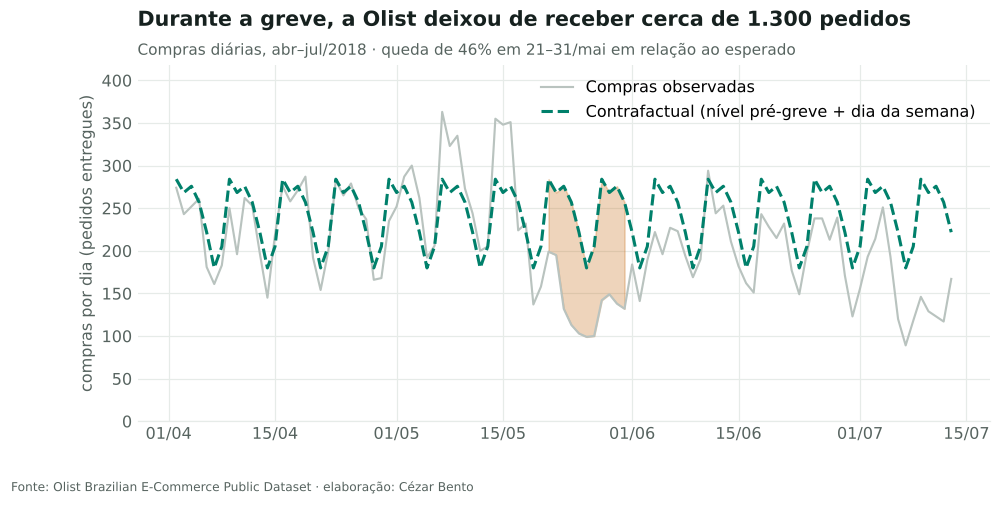

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(y_v.index, y_v.values, color=COR["contexto"], lw=1.4, label="Compras observadas")
ax.plot(cf_v.index, cf_v.values, color=COR["principal"], lw=2, ls="--", label="Contrafactual (nível pré-greve + dia da semana)")
ax.fill_between(y_v.index[jv], y_v[jv], cf_v[jv], color=COR["destaque"], alpha=0.3)
ax.set_ylabel("compras por dia (pedidos entregues)"); ax.set_ylim(0, y_v.max() * 1.15); ax.legend(loc="upper right")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
ax.set_title(f"Durante a greve, a Olist deixou de receber cerca de {br(round(perdidas, -2))} pedidos")
subtitulo(ax, f"Compras diárias, abr–jul/2018 · queda de {perdidas / cf_v[jv].sum():.0%} em 21–31/mai em relação ao esperado")
fonte(fig, FONTE)
fig.savefig(FIG + "15_greve_compras.png")

## Conclusões

| Pergunta | Ferramenta | Resposta |
|---|---|---|
| Por que o atraso quadruplicou em fev–mar? | Decomposição taxa × composição e simulação por etapa | Piora do **transporte** em todas as regiões; vendedor, promessa e mistura de destinos explicam quase nada |
| Quanto a greve atrasou as entregas? | Série temporal interrompida + análise de sensibilidade | Entre 1 e 3 dias a mais de transporte em média na janela, conforme a especificação; mais de 4 dias para os pacotes postados na véspera |
| A greve foi fora do comum? | Placebos no tempo | Entre os maiores desvios (3º de 61 janelas, p ≈ 0,05), mas o ruído de 2017 produziu desvios parecidos |
| Quanto custou em vendas? | ITS sobre as compras diárias | Cerca de metade das compras esperadas na janela não aconteceu |

**Limitações:**
- A ITS supõe que, sem a greve, a série seguiria o padrão anterior. Outros eventos na mesma janela (como a Copa, que começou em junho) entram no pós-período, não no efeito da greve.
- As compras contam só pedidos que chegaram a ser entregues; se a greve aumentou os cancelamentos, parte da queda medida é cancelamento, não compra que deixou de acontecer.
- As compras perdidas podem ter sido só adiadas para depois da greve; o termo de nível "depois" ajuda a ver isso, mas não separa adiamento de perda definitiva.
- O diagnóstico da Parte 1 localiza a etapa, não a causa externa: essa confirmação precisa de dados das transportadoras.